# Corporate Bonds in March 2020

```{admonition} In this guide
:class: tip
**The corporate bond market came close to breaking in March 2020.** In four
weeks the credit spread of the median investment-grade bond went from 85
basis points to 380.

**It was not only about default.** The safest bonds were hit hardest in
proportion, short-maturity bonds traded at wider spreads than long ones,
and investment-grade bonds became more expensive to trade than junk. Those
are the marks of investors selling what they could to raise cash.

**On March 23 the Federal Reserve said it would buy corporate bonds, and
the market turned that day.** The Fed's first purchase came seven weeks
later.

**Every number here comes from three months of TRACE,** cleaned month by
month, in parallel, on the university's cluster.
```

Last week's argument for the cluster was about size: the TRACE record of
corporate bond trades is too big to clean comfortably on a laptop. This
guide is the reason to bother. It uses the cleaned data to look at one
episode, day by day, and asks three questions. What happened to corporate
bonds in March 2020? Was it fear of default, or something else? And what
did the Federal Reserve's announcement do?

In [1]:
import os
import sys
from pathlib import Path

# Make src/ importable whether this runs from the project root or from _output/.
_cwd = Path.cwd()
for _p in [_cwd / "src", _cwd.parent / "src", _cwd]:
    if (_p / "settings.py").exists():
        sys.path.insert(0, str(_p))
        os.chdir(_p.parent)
        break

import matplotlib.pyplot as plt
import pandas as pd

import plot_credit_spreads_march_2020 as figures

plt.rcParams.update({"figure.dpi": 130, "font.size": 11})
pd.set_option("display.float_format", "{:,.0f}".format)

# The tables were computed by src/calc_march_2020.py from the cleaned panel.
daily = figures.load_table("daily_by_class")
by_rating = figures.load_table("spreads_by_rating")
by_maturity = figures.load_table("daily_by_maturity")
trading_cost = figures.load_table("daily_trading_cost")
counts = figures.load_table("monthly_counts")

## 1. Credit spreads

A corporate bond pays a higher yield than a Treasury bond of the same
maturity. The difference is the bond's **credit spread**:

$$
\text{credit spread} = y_{\text{corporate bond}} - y_{\text{Treasury of the same maturity}}
$$

where $y$ is a yield.

It is what investors are paid for two things a Treasury does not have: the
chance that the company defaults, and the difficulty of selling the bond
quickly at a fair price. Spreads are quoted in **basis points**, hundredths
of a percent, so a spread of 150 basis points is 1.5%.

A bond's price and its yield move in opposite directions. If a bond's credit
spread widens while Treasury yields stay where they are, the bond's yield has
gone up and its **price has fallen**. A chart of spreads rising is a chart of
bond prices falling.

Bonds are grouped by credit rating. **Investment grade** is BBB- and above.
**High yield**, also called junk, is everything below. High-yield issuers are
more likely to default, so their spreads are wider.

## 2. The data

TRACE records every trade in a U.S. corporate bond. We use February, March,
and April of 2020. The raw feed has about two million trade reports a month.
The cleaned panel keeps far fewer, for three reasons that week 7 covered:

- Reports that were later cancelled or corrected are removed, along with
  the second copy of trades that a dealer arranged as an agent and reported
  twice.
- Bonds outside the standard research universe are dropped: convertibles,
  floating-rate notes, asset-backed bonds, and others.
- Very small trades, under \$10,000, are dropped. Their prices are not
  representative of what an institution pays.

The result is a daily panel: one row per bond per day it traded, with its
average price, its yield and credit spread, its rating, and the average
prices at which customers bought and sold.

In [2]:
counts_table = counts.to_pandas()
counts_table["month"] = counts_table["month"].dt.strftime("%B %Y")
counts_table = counts_table.set_index("month").rename(
    columns={
        "raw_reports": "Trade reports in the raw feed",
        "raw_bonds": "Bonds in the raw feed",
        "clean_trades": "Trades in the cleaned panel",
        "clean_bonds": "Rated bonds in the cleaned panel",
    }
)
counts_table.index.name = None
counts_table.style.format("{:,}")

,Trade reports in the raw feed,Bonds in the raw feed,Trades in the cleaned panel,Rated bonds in the cleaned panel
February 2020,"1,912,064","24,157","601,816","8,969"
March 2020,"2,453,396","25,479","732,133","9,058"
April 2020,"2,319,809","22,487","713,142","9,068"


About nine thousand bonds and six to seven hundred thousand trades a month.
March has the most trades. Hold on to that: whatever went wrong in March,
the market did not close.

## 3. What happened

The figure shows, for each day, the credit spread of the median
investment-grade bond and of the median high-yield bond, and below it the
number of trades.

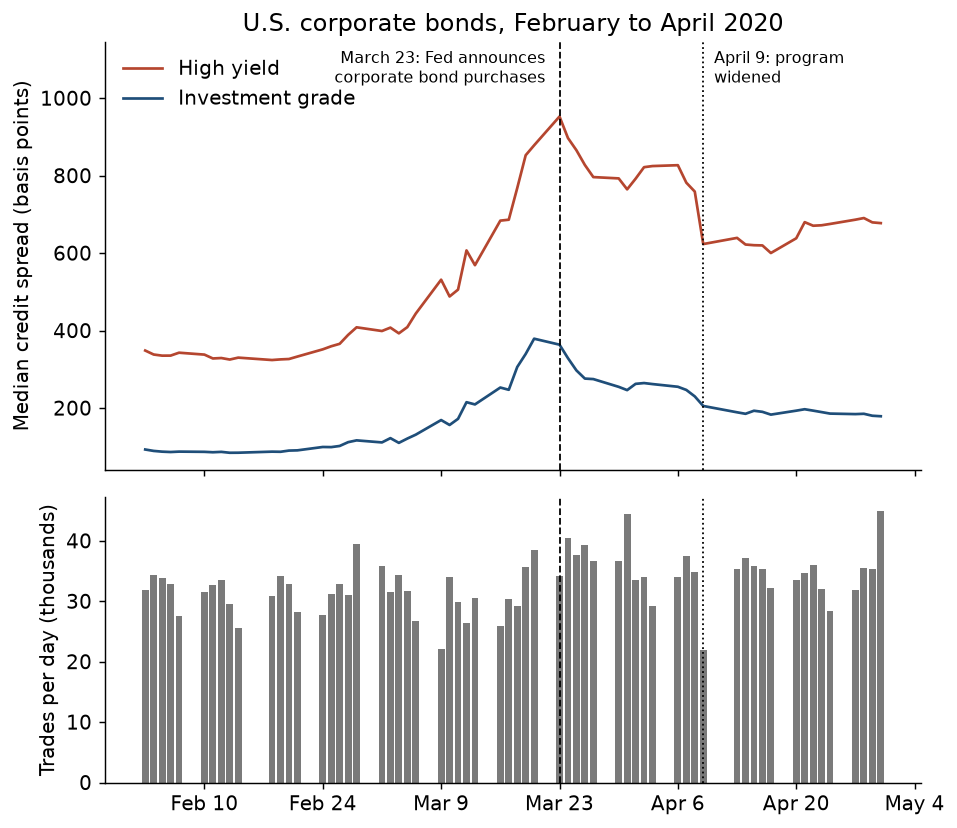

In [3]:
fig = figures.plot_spreads_and_trades(daily)
plt.show()

Read it from left to right.

**Mid-February: calm.** The median investment-grade bond trades at a spread
of about 85 basis points, and the median high-yield bond at about 330.

**Late February to March 20: spreads widen every week, then every day.** As
the pandemic reaches the United States, bond prices fall. On March 20 the
median investment-grade spread is about 380 basis points, more than four
times its February level. The median high-yield spread peaks on March 23 at
about 950. These were the widest spreads since the financial crisis of 2008
and 2009.

**March 23: the turn.** Before the market opens, the Federal Reserve
announces that it will buy investment-grade corporate bonds. The
investment-grade spread falls that day and keeps falling, to about 245 at
the end of March.

**April 9: a second step down.** The Fed widens the program to reach some
high-yield bonds. The median high-yield spread falls by more than 130 basis
points in that one day.

The lower panel is the surprise. Trading did not dry up in the worst weeks.
The week of March 16 had about as many trades as a typical week in
February, and the week of March 23 had the most of the whole period. Bonds
were changing hands, at much worse prices.

```{admonition} Stop and discuss
:class: note
Spreads quadrupled in a month. Give two different stories for why a
corporate bond's price would fall that far that fast. For each story, which
bonds should fall the most?
```

## 4. Which bonds were hit hardest?

One story is **default**. A pandemic closes businesses, some companies will
not repay, and investors demand more to hold their bonds. If that is the
whole story, the weakest companies should be hit hardest, and the bonds of
the strongest should hardly move. Nobody thought in March 2020 that
Microsoft or Johnson & Johnson was about to default.

The table shows the median spread by rating, on a calm day in February, at
the peak, and after each announcement. The last column is the spread at the
peak divided by the spread in February.

In [4]:
rating_table = by_rating.to_pandas().set_index("rating_bucket")
rating_table.index.name = None
rating_table.columns = [
    pd.Timestamp(c).strftime("%b %-d") for c in rating_table.columns
]
rating_table["Mar 20 as a multiple of Feb 14"] = (
    rating_table["Mar 20"] / rating_table["Feb 14"]
)
rating_table.style.format("{:,.0f}").format(
    "{:.1f}x", subset=["Mar 20 as a multiple of Feb 14"]
)

,Feb 14,Mar 20,Mar 23,Mar 31,Apr 8,Apr 9,Apr 30,Mar 20 as a multiple of Feb 14
AAA and AA,36,258,229,140,126,108,97,7.1x
A,63,328,304,198,180,157,141,5.2x
BBB,110,473,446,318,307,281,253,4.3x
BB,276,780,842,647,666,537,580,2.8x
B,442,"1,061","1,185",936,986,837,871,2.4x
CCC and below,"1,003","2,667","3,055","3,007","2,838","2,841","4,292",2.7x


In basis points, the riskiest bonds moved the most, as they always do. In
proportion, it is the other way around. The spread on bonds rated AAA and AA
rose about **sevenfold**. The spread on bonds rated B rose less than
threefold.

A sevenfold rise in the spread of the safest companies in the country is
hard to explain by default alone. The default story predicts the ranking in
the last column upside down.

The table also shows who the announcements reached. From March 20 to March
31, every investment-grade row falls by about a third or more. The BB and B rows
are still rising on March 23, and their large one-day fall is from April 8
to April 9, when the program was widened to them. The lowest row, CCC and
below, which no program covered, does not recover at all.

## 5. The credit curve turned upside down

Normally a company pays a wider spread to borrow for thirty years than for
two. More can go wrong over thirty years. So the spread rises with maturity,
and in February it does: about 40 basis points for investment-grade bonds
with under three years to run, and about 135 for those with more than ten.

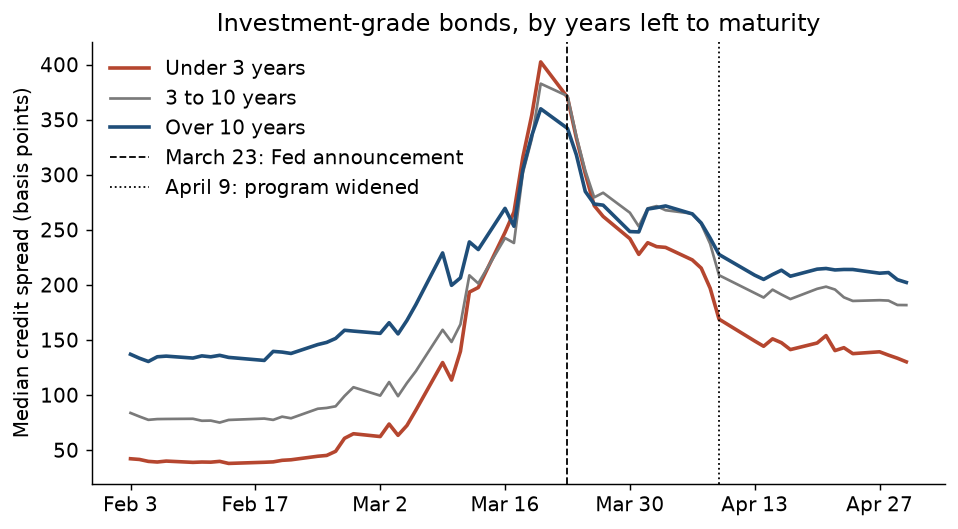

In [5]:
fig = figures.plot_spreads_by_maturity(by_maturity)
plt.show()

In March the lines cross. On March 20 the shortest bonds have the *widest*
spread, about 400 basis points, ten times their February level. The longest
bonds, which have the most exposure to a company's long-run fate, moved the
least.

This is a second fact the default story cannot produce. A two-year bond of a
company with a strong balance sheet is close to cash. That is the reason it
was sold. An investor who needs money today sells the holding that is
easiest to sell and loses the least when sold, and in March 2020 everyone
needed money on the same day. Bond mutual funds, facing withdrawals, were
the largest sellers.

```{admonition} Stop and discuss
:class: note
If short-maturity, high-grade bonds are the easiest to sell, why did their
prices fall the most? Who is supposed to be on the other side of those
sales, and what would stop them from buying?
```

## 6. What it cost to trade

Corporate bonds do not trade on an exchange. An investor who wants to sell
calls a **dealer**, usually a bank, which buys the bond for its own account
and holds it until it finds a buyer. The dealer is paid by the gap between
the price at which it buys and the price at which it sells.

TRACE says, for each trade, whether the customer was buying or selling. So
for every bond that customers both bought and sold on the same day, we can
measure that gap: the average price customers paid, minus the average price
customers received, as a share of the price. It is what a customer would
lose by buying a bond from a dealer and selling it straight back. The figure
shows the median across bonds, each day.

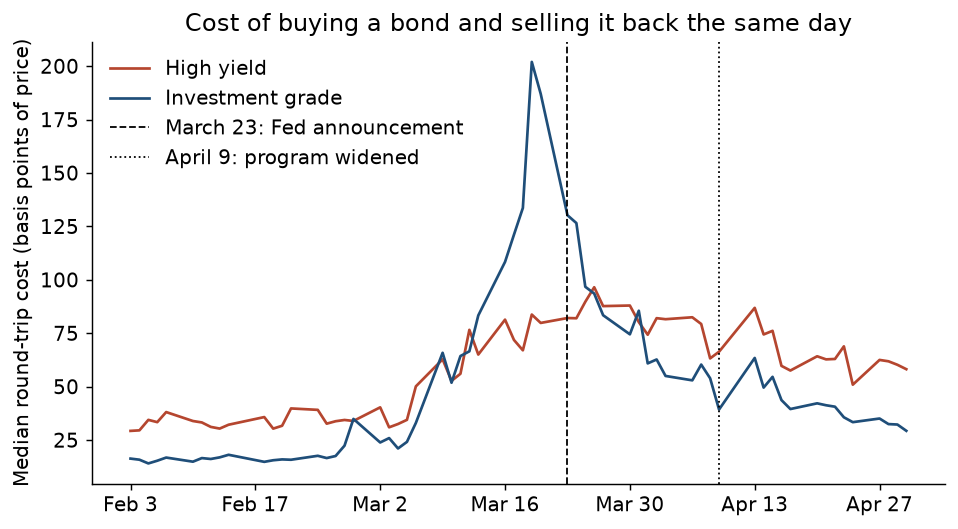

In [6]:
fig = figures.plot_trading_cost(trading_cost)
plt.show()

In February a round trip in an investment-grade bond costs under 20 basis
points, about half of what it costs in a high-yield bond. That is the
normal order: safer bonds are cheaper to trade.

In the third week of March the investment-grade cost reaches about **200
basis points, more than ten times its February level,** and more than twice
the cost of trading junk. Dealers were being asked to buy far more
investment-grade bonds than they had room to hold, and they charged for it.

On March 23 the investment-grade cost drops by about a third in one day,
and it keeps falling: under 90 basis points within a week, about 40 by
mid-April. The high-yield cost does not
spike as far and does not come down as fast. Again the order of events
follows the order of the announcements.

This is the measure O'Hara and Zhou (2021) build, with more care than we
take here: they separate trades by size and by which dealer was involved,
and show that the cost fell first for the bonds the Fed's program covered.

## 7. What the Fed did, and when

**March 23.** The Federal Reserve announced the Primary and the Secondary
Market Corporate Credit Facility, under which it would lend to
investment-grade companies and buy their bonds, and buy exchange-traded
funds that hold such bonds. The Fed had never bought corporate bonds before.

**April 9.** It enlarged the facilities and extended them to companies that
had been investment grade on March 22 and were downgraded afterward, and to
funds that hold high-yield bonds.

**May 12.** The Fed made its first purchase, of bond funds. Its first
purchases of individual bonds were in mid-June.

So for seven weeks the Fed bought nothing, and prices recovered anyway. What
changed on March 23 was what investors expected. A buyer with no limit on
its balance sheet had said it would be there. That made it safe for dealers
to hold bonds again and pointless for investors to sell first, and the
selling stopped.

```{admonition} Stop and discuss
:class: note
The Fed moved prices for seven weeks by promising to buy. What had to be
true about the Fed for that promise to work? Could a large pension fund have
done the same thing with the same announcement?
```

## 8. Why this needed clean data, and a cluster

Every exhibit above is a median or a count across thousands of bonds, taken
day by day. Drawn from the raw feed, each would be wrong in a way that
matters most in exactly these weeks:

- **Counts.** The raw feed keeps a trade that was cancelled or corrected
  beside its replacement, and reports agency trades twice. The trade counts
  would be too high, by a different amount each day.
- **Prices.** A price entered with the decimal point in the wrong place
  becomes a yield, then a spread, then a trading cost. When real prices move
  several percent in a day, an error and a real trade look alike, and the
  filters that separate them are judgment calls. The defense is a cleaning
  procedure that is written down, tested, and can be run again.

The cleaning is independent by month: March's trades do not depend on
February's. So the three months, for two TRACE feeds, were cleaned as six
tasks at the same time on Midway3, in about two minutes. A second job then
followed each bond through time to add its yield, spread, and rating, and
built the tables this guide reads. How to run work that way is the rest of
this week.

## Takeaways

- A credit spread is a corporate bond's yield over a matching Treasury. A
  wider spread is a lower price.
- In March 2020 spreads reached their widest since 2008 and 2009, while
  trading continued.
- Three facts point to forced selling and strained dealers, not only to
  default: the safest bonds were hit hardest in proportion, short bonds
  traded wider than long ones, and investment-grade bonds became costlier to
  trade than high-yield bonds.
- Spreads and trading costs turned on March 23, the day of the Fed's
  announcement, and high-yield spreads on April 9, when the program was
  widened. The purchases themselves began in May.

## References

- Haddad, V., Moreira, A., & Muir, T. (2021).
  [When selling becomes viral: Disruptions in debt markets in the COVID-19 crisis and the Fed's response](https://ideas.repec.org/a/oup/rfinst/v34y2021i11p5309-5351..html).
  *Review of Financial Studies*, 34(11), 5309--5351.
- O'Hara, M., & Zhou, X. A. (2021).
  [Anatomy of a liquidity crisis: Corporate bonds in the COVID-19 crisis](https://doi.org/10.1016/j.jfineco.2021.05.052).
  *Journal of Financial Economics*, 142(1), 46--68.
- Dick-Nielsen, J. (2014). How to clean Enhanced TRACE data. Working paper.
  The cancellation, correction, and agency-trade filters.

```{admonition} Notes on the discussion questions
**Two stories.** One is default: the pandemic makes it more likely that
companies cannot repay. That story says the weakest companies' bonds fall
the most and the strongest hardly move. The other is selling pressure:
investors need cash, sell what they can, and dealers cannot absorb it. That
story says the bonds that are easiest to sell fall the most, whatever the
company's health. Sections 4 to 6 are three tests between them.

**Why the easiest bonds to sell fell the most.** Because they were the ones
sold. The other side of the trade is a dealer, and a dealer's room to hold
bonds is limited by its capital and its own risk limits. When every customer
sells at once, dealers fill up, and the price has to fall far enough to
bring in a buyer from outside the usual market.

**Why the promise worked.** The Fed can create the money it buys with, so
no amount of selling can exhaust it, and everyone knows that. A pension
fund's promise is only as large as its assets. Sellers who believe the buyer
cannot run out have no reason to sell first, and dealers who believe it can
always sell to that buyer are willing to hold bonds again.
```